# Multi-Criteria Analysis (MCA) Lab — Net-Zero 2050 Policy Options

In this lab you use **Multi-Criteria Analysis (MCA)** to compare pathways towards **net-zero emissions by 2050**.
MCA is particularly useful when options are assessed against multiple criteria measured in different units (€, MtCO₂e, %, jobs, …), and when stakeholders have different priorities. It makes trade-offs explicit and helps explore how those priorities affect the preferred option.

The notebook walks through the full MCA workflow on a small worked example. You then reuse the same code with data from your own project.

```
Raw data  ──►  Normalize (0–100)  ──►  Weight  ──►  Aggregate (weighted sum)  ──►  Test robustness
Section 1      Section 2               Section 3    Section 4                      Section 5
```

### Learning goals
After this lab you should be able to:
- define decision **alternatives** and evaluation **criteria**, and decide for each criterion whether more is better or worse;
- **normalize** indicators with different units onto a common 0–100 scale, and explain what 0 and 100 mean;
- apply and justify a **weighting** scheme, and compute an aggregate **weighted-sum** score;
- explain **why** an alternative ranks where it does (which criteria drive its score);
- test how **robust** a ranking is to different stakeholder priorities.

### How to use this notebook
- Run all cells from top to bottom (Colab: *Runtime → Run all*).
- Cells marked **✏️ EDIT** hold the inputs you change: `raw_data` and `criterion_meta` (Section 1), `direct_weights` (Section 3) and the alternative weight sets (Section 5). All other cells update automatically.

### Two ways to apply MCA in your project

| | **Path A — Scenario level** | **Path B — Technology level** |
|---|---|---|
| **Alternatives** | Integrated policy pathways from an energy-system model (e.g. *Net-Zero 2050*, *Current Policies*) | Technologies or projects (e.g. Solar PV, Onshore Wind, Gas + CCS) |
| **Typical criteria** | System-wide outcomes: emissions, system cost, jobs, energy poverty, public acceptance | Technology properties: LCOE, CO₂ intensity, land/water use, social acceptance |
| **Question answered** | *Which national pathway best balances climate, economic and social goals?* | *Which technologies should play a larger or smaller role in the mix, given national conditions?* |
| **Use when** | You want strategic, cross-sector policy advice | Scenario results are too similar, or you want to look at the power mix in more detail |

The worked example below follows **Path A**. The code also works for Path B: only the inputs change.
Whichever path you choose, keep a clear link between the **model numbers** and your **qualitative reasoning** about social, environmental and institutional factors.

## 0.) Setup
Colab and the course environment already include these packages, so nothing needs to be installed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

pd.set_option("display.precision", 2)

# Plot style: light grid, no top/right frame
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 14,
})
# Colour-blind-safe colours, always used in this order
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MARKERS = "osD^v<>p"

## 1.) Define alternatives and criteria

The worked example compares four **alternatives**, i.e. policy pathways that a national energy-system model could produce.
The numbers are **illustrative only**. They are not model results.

| Alternative | Storyline |
|---|---|
| `NZ2050_DeepElec` | Net zero by 2050, mainly through deep electrification of transport, heating and industry |
| `NZ2050_Balanced` | Net zero by 2050 through a balanced mix of options |
| `NZ2050_HydrogenPush` | Net zero by 2050 with a strong role for hydrogen |
| `NPI_Current` | *National Policies Implemented*: only policies already in place, so not net zero (the reference case) |

Each alternative is scored on 11 **criteria** in five categories: Technical, Economic, Environmental, Social and Institutional.
Each criterion has a **direction**:
- **benefit**: higher is better (e.g. renewable share, public acceptance);
- **cost**: lower is better (e.g. system cost, GHG emissions).

A wrong direction silently reverses that criterion's effect on the result, so check each one carefully.

In [2]:
# ✏️ EDIT: one row per alternative, one column per criterion
raw_data = pd.DataFrame({
    "Alternative":                      ["NZ2050_DeepElec", "NZ2050_Balanced", "NPI_Current", "NZ2050_HydrogenPush"],
    "Renewable_share_%":                 [85,   75,   55,   70],
    "Annual_storage_additions_GWh":      [25,   18,    6,   22],
    "System_cost_pct_GDP":               [4.2,  3.9,  3.2,  4.5],
    "Household_bill_EUR":                [1350, 1300, 1250, 1450],
    "GHG_2050_MtCO2e":                   [30,   60,  220,   45],
    "Air_pollution_index":               [20,   30,   60,   25],
    "Jobs_change_coal_regions_thousand": [45,   30,  -10,   50],
    "Energy_poverty_rate_%":             [9,     7,    8,   10],
    "Public_acceptance_index":           [55,   70,   65,   60],
    "Implementation_readiness_score":    [65,   70,   90,   45],
    "Regulatory_complexity_index":       [45,   40,   20,   60],
})

# ✏️ EDIT: one row per criterion -> name, direction ("benefit" = higher is better, "cost" = lower is better), category, meaning
criterion_meta = pd.DataFrame([
    ("Renewable_share_%",                 "benefit", "Technical",     "Share of electricity from renewables (%)"),
    ("Annual_storage_additions_GWh",      "benefit", "Technical",     "Storage capacity added per year (GWh)"),
    ("System_cost_pct_GDP",               "cost",    "Economic",      "Total energy-system cost (% of GDP)"),
    ("Household_bill_EUR",                "cost",    "Economic",      "Average annual household energy bill (EUR)"),
    ("GHG_2050_MtCO2e",                   "cost",    "Environmental", "Remaining GHG emissions in 2050 (MtCO2e)"),
    ("Air_pollution_index",               "cost",    "Environmental", "Air-pollution index (higher = more polluted)"),
    ("Jobs_change_coal_regions_thousand", "benefit", "Social",        "Net change in jobs in coal regions (thousands)"),
    ("Energy_poverty_rate_%",             "cost",    "Social",        "Households in energy poverty (%)"),
    ("Public_acceptance_index",           "benefit", "Social",        "Public-acceptance index (higher = more accepted)"),
    ("Implementation_readiness_score",    "benefit", "Institutional", "Institutional readiness to implement (score)"),
    ("Regulatory_complexity_index",       "cost",    "Institutional", "Regulatory complexity (higher = more complex)"),
], columns=["criterion", "direction", "Category", "description"])

In [3]:
# Check the inputs, then show everything in one table (criteria as rows, alternatives as columns)
crit = list(criterion_meta["criterion"])
mismatch = set(crit) ^ set(raw_data.columns.drop("Alternative"))
assert not mismatch, f"Criterion names differ between raw_data and criterion_meta: {mismatch}"
assert criterion_meta["direction"].isin(["benefit", "cost"]).all(), "direction must be 'benefit' or 'cost'"
assert raw_data[crit].notna().all().all(), "raw_data contains missing values"

raw = raw_data.set_index("Alternative")[crit]   # alternatives × criteria, in criterion_meta order
meta = criterion_meta.set_index("criterion")

meta.join(raw.T.map("{:g}".format))

,direction,Category,description,NZ2050_DeepElec,NZ2050_Balanced,NPI_Current,NZ2050_HydrogenPush
criterion,,,,,,,
Renewable_share_%,benefit,Technical,Share of electricity from renewables (%),85,75,55,70
Annual_storage_additions_GWh,benefit,Technical,Storage capacity added per year (GWh),25,18,6,22
System_cost_pct_GDP,cost,Economic,Total energy-system cost (% of GDP),4.2,3.9,3.2,4.5
Household_bill_EUR,cost,Economic,Average annual household energy bill (EUR),1350,1300,1250,1450
GHG_2050_MtCO2e,cost,Environmental,Remaining GHG emissions in 2050 (MtCO2e),30,60,220,45
Air_pollution_index,cost,Environmental,Air-pollution index (higher = more polluted),20,30,60,25
Jobs_change_coal_regions_thousand,benefit,Social,Net change in jobs in coal regions (thousands),45,30,-10,50
Energy_poverty_rate_%,cost,Social,Households in energy poverty (%),9,7,8,10
Public_acceptance_index,benefit,Social,Public-acceptance index (higher = more accepted),55,70,65,60


## 2.) Normalization (0–100 scale)

The criteria have different units, so they cannot simply be added up. **Min–max normalization** rescales every criterion to 0–100,
where **100 is always the best value and 0 always the worst**:

$$
\text{benefit:}\quad x'_{a,c} = 100\cdot\frac{x_{a,c}-\min_c}{\max_c-\min_c}
\qquad\qquad
\text{cost:}\quad x'_{a,c} = 100\cdot\frac{\max_c-x_{a,c}}{\max_c-\min_c}
$$

Here $\min_c$ and $\max_c$ are the lowest and highest values of criterion $c$ **among the alternatives being compared**.

> ⚠️ **The scale is relative, not absolute.** A score of 0 means *worst of these four options*, not *bad* in any absolute sense.
> If you add or remove an alternative, $\min_c$ and $\max_c$ can change, and every score can change with them.

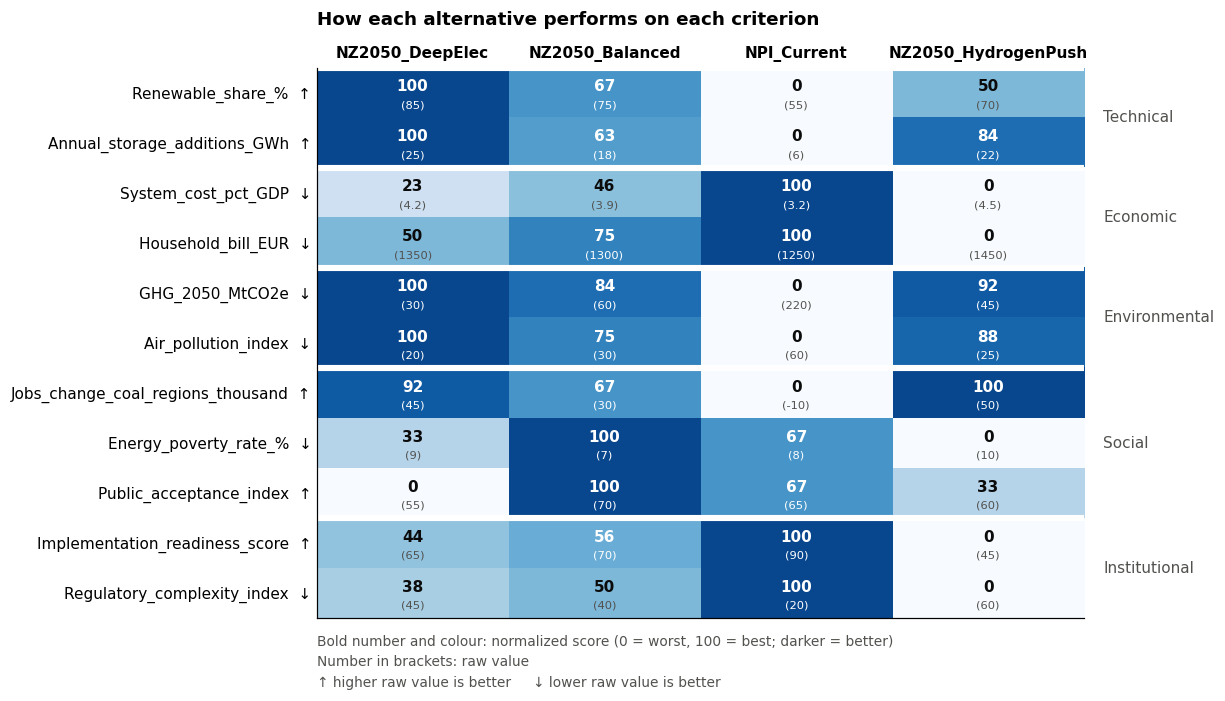

In [4]:
def normalize_minmax(raw, meta):
    # Rescale each criterion to 0–100 (100 = best alternative, 0 = worst)
    lo, hi = raw.min(), raw.max()
    norm = 100 * (raw - lo) / (hi - lo)              # benefit: higher raw value -> higher score
    cost = meta.index[meta["direction"] == "cost"]
    norm[cost] = 100 - norm[cost]                    # cost: flip, so lower raw value -> higher score
    return norm.fillna(100)                          # criterion equal for all alternatives (0/0) -> no difference

normalized = normalize_minmax(raw, meta)

# Heatmap: colour and bold number = normalized score, small number in brackets = raw value
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.imshow(normalized.T, cmap="Blues", vmin=0, vmax=110, aspect="auto")
ax.grid(False)
ax.tick_params(length=0)
ax.set_xticks(range(len(raw)), raw.index, weight="bold")
ax.xaxis.tick_top()
ax.set_yticks(range(len(crit)), [f"{c}  {'↑' if meta.loc[c, 'direction'] == 'benefit' else '↓'}" for c in crit])
for i, c in enumerate(crit):
    for j, a in enumerate(raw.index):
        s = normalized.loc[a, c]
        ax.text(j, i - 0.12, f"{s:.0f}", ha="center", va="center", fontsize=10, weight="bold", color="white" if s > 55 else "#0b0b0b")
        ax.text(j, i + 0.25, f"({raw.loc[a, c]:g})", ha="center", va="center", fontsize=7.5, color="white" if s > 55 else "#52514e")
cats = meta["Category"]
for cat in cats.unique():                            # white line + label for each category block
    rows = np.flatnonzero(cats == cat)
    ax.axhline(rows[0] - 0.5, color="white", lw=4)
    ax.text(len(raw) - 0.4, rows.mean(), cat, va="center", color="#52514e")
ax.set_title("How each alternative performs on each criterion")
ax.text(0, -0.03, "Bold number and colour: normalized score (0 = worst, 100 = best; darker = better)\n"
        "Number in brackets: raw value\n"
        "↑ higher raw value is better     ↓ lower raw value is better",
        transform=ax.transAxes, va="top", fontsize=9, color="#52514e", linespacing=1.6)
plt.show()

**Reading the heatmap.** No alternative is best on everything. `NZ2050_DeepElec` leads on the environmental and technical criteria,
`NPI_Current` on cost and ease of implementation, `NZ2050_Balanced` on energy poverty and public acceptance, and `NZ2050_HydrogenPush` on jobs in coal regions.
The ranking will therefore depend on how the criteria are weighted.

## 3.) Weighting the criteria

Weights determine how much each criterion counts in the final score. They are **value judgements**: a finance ministry, an environmental NGO
and a coal-region trade union would each choose different weights. MCA does not remove this subjectivity. It makes it **explicit and testable**.

Two things to keep in mind:
- The weights must sum to 1. The code rescales them if they don't, and prints a note.
- With min–max normalization, a weight is the value of moving from the **worst to the best alternative** on that criterion.
  So check how large that gap actually is before choosing a weight. For GHG emissions the gap is 30 vs 220 MtCO₂e; for energy poverty it is only 7 % vs 10 %.

In [5]:
# ✏️ EDIT: importance weights (should sum to 1.0)
direct_weights = {
    "Renewable_share_%":                 0.08,
    "Annual_storage_additions_GWh":      0.07,
    "System_cost_pct_GDP":               0.12,
    "Household_bill_EUR":                0.08,
    "GHG_2050_MtCO2e":                   0.25,
    "Air_pollution_index":               0.10,
    "Jobs_change_coal_regions_thousand": 0.10,
    "Energy_poverty_rate_%":             0.05,
    "Public_acceptance_index":           0.07,
    "Implementation_readiness_score":    0.05,
    "Regulatory_complexity_index":       0.03,
}

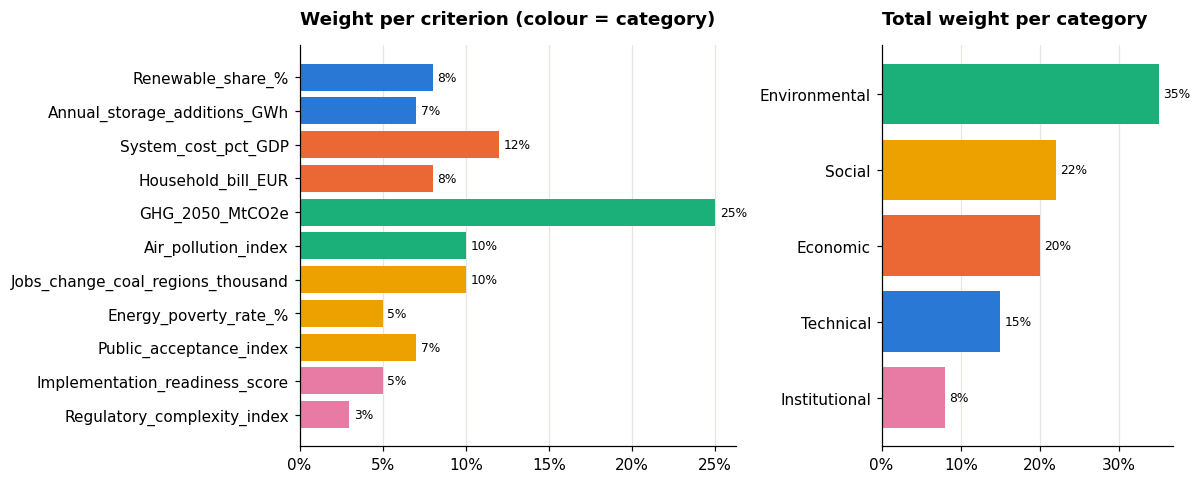

In [6]:
def as_weights(weights):
    # Turn a {criterion: weight} dict into a Series in criterion order that sums to 1
    mismatch = set(weights) ^ set(crit)
    assert not mismatch, f"Weight names differ from criterion_meta: {mismatch}"
    w = pd.Series(weights)[crit]
    if not np.isclose(w.sum(), 1.0):
        print(f"Note: weights summed to {w.sum():.3f} and were rescaled to 1.0")
    return w / w.sum()

w_direct = as_weights(direct_weights)

cat_colors = dict(zip(cats.unique(), PALETTE))       # one fixed colour per category, reused in all plots
cat_weights = w_direct.groupby(cats).sum().sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [3, 2]})
ax1.barh(crit[::-1], w_direct[crit[::-1]], color=cats[crit[::-1]].map(cat_colors))
ax1.set_title("Weight per criterion (colour = category)", loc="left")
ax2.barh(cat_weights.index, cat_weights, color=cat_weights.index.map(cat_colors))
ax2.set_title("Total weight per category", loc="left")
for ax in (ax1, ax2):
    ax.bar_label(ax.containers[0], fmt="{:.0%}", padding=3, fontsize=8)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 4.) Aggregate index — weighted sum

The overall score of alternative $a$ is the weighted sum of its normalized scores:

$$ S_a = \sum_c w_c \, x'_{a,c} \qquad (0 \le S_a \le 100) $$

A score of 100 would mean *best on every criterion*. The weighted sum is **compensatory**: a poor score on one criterion can be made up by good scores on others.
Ask yourself whether that is acceptable. For example, should enough job creation be able to compensate for very high emissions?

In [7]:
scores = (normalized @ w_direct).rename("MCA_WeightedSum_0to100")   # matrix product = weighted sum per alternative
scores.sort_values(ascending=False).to_frame()

,MCA_WeightedSum_0to100
Alternative,
NZ2050_Balanced,72.79
NZ2050_DeepElec,70.95
NZ2050_HydrogenPush,54.00
NPI_Current,36.00


### What drives each score?
Each bar segment shows how many points a category contributes to the total, i.e. $w_c \, x'_{a,c}$ summed over the criteria in that category.
Use this chart to explain *why* an alternative ranks where it does.

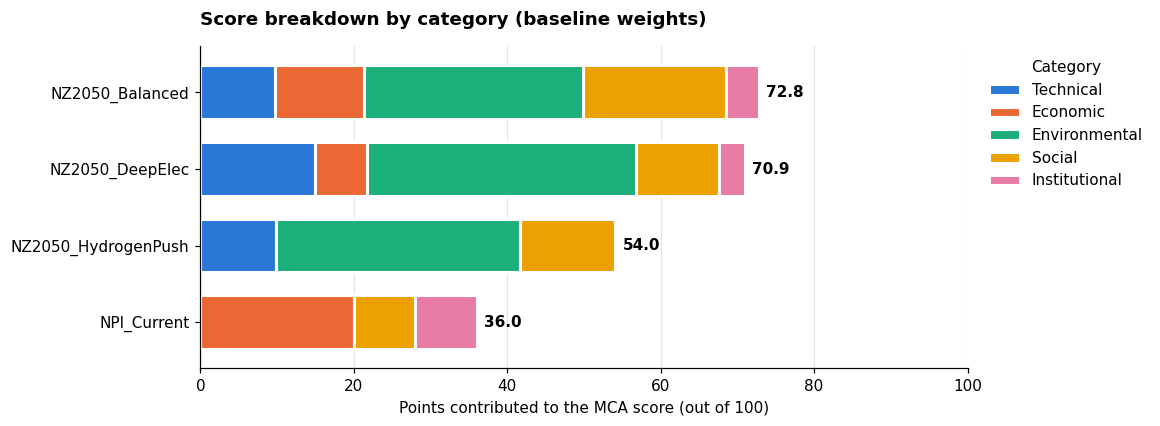

In [8]:
contrib = normalized * w_direct                                      # points contributed by each criterion
by_cat = contrib.T.groupby(cats).sum().T[list(cat_colors)]           # summed per category
by_cat = by_cat.loc[scores.sort_values().index]                      # best alternative at the top

ax = by_cat.plot.barh(stacked=True, color=cat_colors, figsize=(9, 3.8), width=0.7, edgecolor="white", linewidth=2)
for y, total in enumerate(scores[by_cat.index]):
    ax.text(total + 1, y, f"{total:.1f}", va="center", weight="bold")
ax.set(xlim=(0, 100), xlabel="Points contributed to the MCA score (out of 100)", ylabel="")
ax.set_title("Score breakdown by category (baseline weights)", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.show()

For example, `NZ2050_Balanced` edges out `NZ2050_DeepElec` by being cheaper and more socially acceptable, while DeepElec collects the most environmental and technical points.
`NPI_Current` scores well on cost and ease of implementation but gets nothing from the Environmental and Technical criteria, where it is the worst option.

## 5.) Comparing results under different weight sets

How **sensitive** is the ranking to stakeholder priorities? Here we compare the baseline weights with two alternative perspectives:
- **Environmental priority:** more weight on GHG emissions and air pollution.
- **Economic priority:** more weight on system cost and household bills.

In [9]:
# ✏️ EDIT: alternative weight sets (add more perspectives in the same way)
weights_env_priority = {
    "Renewable_share_%": 0.08, "Annual_storage_additions_GWh": 0.06,
    "System_cost_pct_GDP": 0.05, "Household_bill_EUR": 0.05,
    "GHG_2050_MtCO2e": 0.35, "Air_pollution_index": 0.15,
    "Jobs_change_coal_regions_thousand": 0.07, "Energy_poverty_rate_%": 0.04, "Public_acceptance_index": 0.05,
    "Implementation_readiness_score": 0.07, "Regulatory_complexity_index": 0.03,
}
weights_econ_priority = {
    "Renewable_share_%": 0.06, "Annual_storage_additions_GWh": 0.05,
    "System_cost_pct_GDP": 0.25, "Household_bill_EUR": 0.20,
    "GHG_2050_MtCO2e": 0.15, "Air_pollution_index": 0.05,
    "Jobs_change_coal_regions_thousand": 0.07, "Energy_poverty_rate_%": 0.05, "Public_acceptance_index": 0.02,
    "Implementation_readiness_score": 0.07, "Regulatory_complexity_index": 0.03,
}

weight_sets = pd.DataFrame({
    "Environmental": as_weights(weights_env_priority),
    "Baseline":      w_direct,
    "Economic":      as_weights(weights_econ_priority),
})

What each perspective means in terms of **category** weights:

In [10]:
weight_sets.groupby(cats).sum().loc[list(cat_colors)]

,Environmental,Baseline,Economic
Category,,,
Technical,0.14,0.15,0.11
Economic,0.10,0.20,0.45
Environmental,0.50,0.35,0.20
Social,0.16,0.22,0.14
Institutional,0.10,0.08,0.10


In [11]:
scores_by_set = normalized @ weight_sets                                  # alternatives × weight sets
ranks = scores_by_set.rank(ascending=False, method="min").astype(int)

summary = scores_by_set.add_suffix(" score").join(ranks.add_suffix(" rank"))
summary["ΔRank (max − min)"] = ranks.max(axis=1) - ranks.min(axis=1)
summary.sort_values("Baseline rank")

,Environmental score,Baseline score,Economic score,Environmental rank,Baseline rank,Economic rank,ΔRank (max − min)
Alternative,,,,,,,
NZ2050_Balanced,74.96,72.79,67.13,2,1,1,1
NZ2050_DeepElec,79.64,70.95,59.09,1,2,3,2
NZ2050_HydrogenPush,63.08,54.00,33.07,3,3,4,1
NPI_Current,26.00,36.00,59.67,4,4,2,2


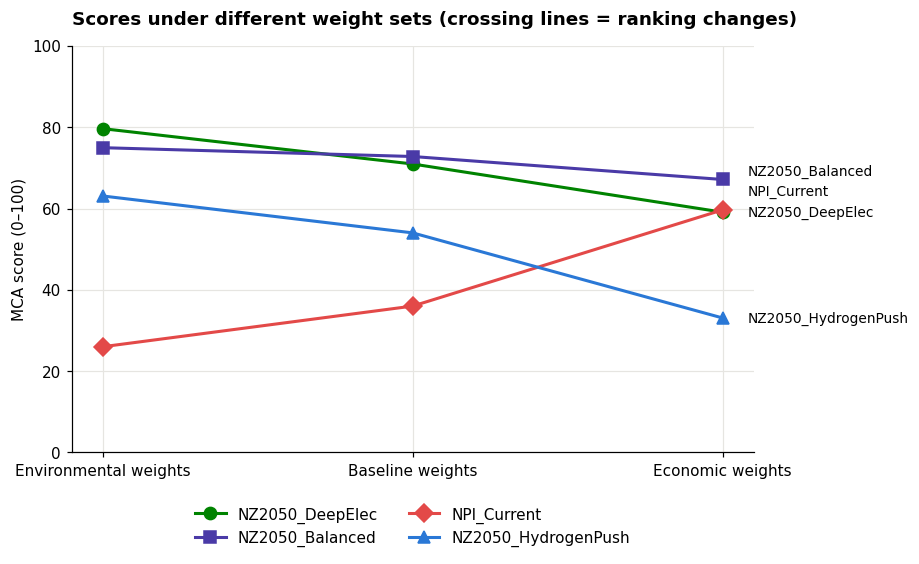

In [12]:
alt_colors = dict(zip(raw.index, PALETTE[5:] + PALETTE[:5]))   # one fixed colour per alternative

ends = scores_by_set.iloc[:, -1].sort_values()
label_y = ends.copy()
for k in range(1, len(ends)):                                  # keep end labels at least 5 points apart
    label_y.iloc[k] = max(ends.iloc[k], label_y.iloc[k - 1] + 5)

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(weight_sets.columns))
for (alt, row), marker in zip(scores_by_set.iterrows(), MARKERS):
    ax.plot(x, row, marker=marker, ms=8, lw=2, color=alt_colors[alt], label=alt)
    ax.annotate(alt, (x[-1], row.iloc[-1]), xytext=(x[-1] + 0.08, label_y[alt]), va="center", fontsize=9)
ax.set_xticks(x, [f"{c} weights" for c in weight_sets.columns])
ax.set(ylim=(0, 100), ylabel="MCA score (0–100)")
ax.set_title("Scores under different weight sets (crossing lines = ranking changes)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.show()

> **How to interpret ΔRank**
> - **ΔRank = 0**: the alternative is **robust**. It keeps its position whatever the perspective.
> - **High ΔRank**: the alternative is **sensitive** to priorities. It does well only under certain value systems.
> - Always check the **score gap** as well as the rank. Under economic weights, `NPI_Current` (59.7) and `NZ2050_DeepElec` (59.1)
>   are less than one point apart, so their difference in rank is effectively a tie. Under baseline weights, `NZ2050_Balanced` leads DeepElec by less than two points.
>
> In your report, discuss whether your recommended alternative is robust or priority-dependent, and which weight set best reflects your country's policy stance or public opinion.

## 6.) Interpreting your results

Write as a **policy analyst advising decision-makers**. MCA does not deliver *the answer*. It gives a transparent, evidence-based structure for reasoning about trade-offs.

**1. The ranking.** `MCA_WeightedSum_0to100` is the overall performance index (0–100, where 100 = best on every criterion) *given your criteria and weights*.
Report the ranking **and** the size of the gaps; a difference of one or two points is effectively a tie.

**2. Drivers and trade-offs.** Use the heatmap (Section 2) and the score breakdown (Section 4):
- Which criteria drive the top alternative's score (e.g. low emissions, job creation)? Where is it weaker (e.g. higher cost, slower implementation)?
- Where do lower-ranked options still have advantages, such as lower cost or easier implementation?

**3. Robustness.** Use the ΔRank table and the score chart in Section 5:
- Which alternatives stay on top under every perspective (robust), and which depend on one value system (sensitive)?
- Would a modest change in the weights overturn your recommendation? Try adjusting the weight sets in Section 5 to find out.

**4. Context.**
- *Path A (scenarios):* discuss whole-economy implications across power, transport, industry and buildings.
- *Path B (technologies):* MCA results do not mean *pick one technology*. Read them as roles in the future mix:
  high-ranking = key pillars; mid-ranking = supporting or niche roles; low-ranking = phase-out candidates or in need of major innovation.
  Consider physical constraints (land, offshore area), system integration (flexibility, intermittency), resources (sun, wind, biomass, CO₂ storage)
  and social or institutional acceptance (e.g. of nuclear or onshore wind).

**5. Policy relevance.** Relate your conclusions to national targets (NDCs, NECPs), EU frameworks (Fit for 55, REPowerEU, Green Deal) and the SDGs
(SDG 7 Affordable & Clean Energy, SDG 13 Climate Action). End with a short, evidence-based statement. For the worked example it could read:

> *Under baseline and economic priorities, NZ2050_Balanced ranks first, thanks to lower costs than the other net-zero pathways, the lowest energy poverty and the highest public acceptance.
> NZ2050_DeepElec achieves the lowest emissions and air pollution, and ranks first when environmental outcomes are prioritised.
> The recommendation therefore hinges on how strongly the government prioritises environmental outcomes over affordability and acceptance.*

Always interpret the results in light of national context, modelling assumptions and social factors.